## Perceptron

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from mlxtend.plotting import plot_decision_regions

In [2]:
df = pd.read_csv(r"DataSets\placement2.csv")

print(df.shape)
df.head()

(100, 3)


,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


<Axes: xlabel='cgpa', ylabel='resume_score'>

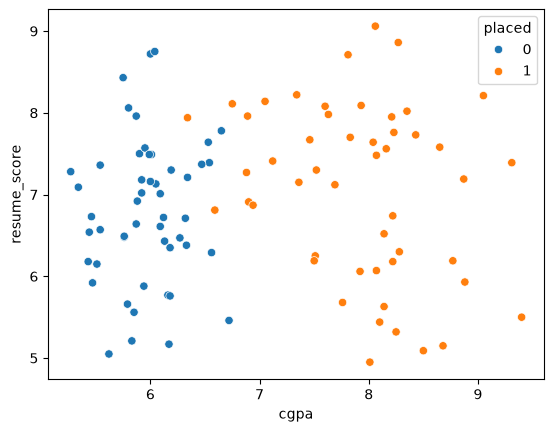

In [3]:
sns.scatterplot(x=df['cgpa'],y=df['resume_score'],hue=df['placed'])

#### Perceptron using library

[[ 40.26 -36.  ]]
[-25.]


c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


<Axes: >

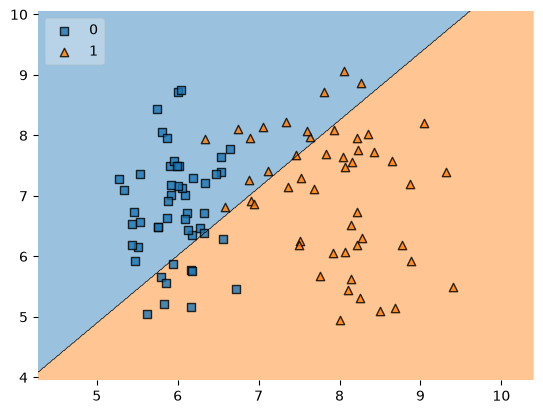

In [4]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

p = Perceptron()
p.fit(X,y)
print(p.coef_)
print(p.intercept_)

plot_decision_regions(X.values, y.values, clf=p, legend=2)

### Perceptron Trick using self code 

In [5]:
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

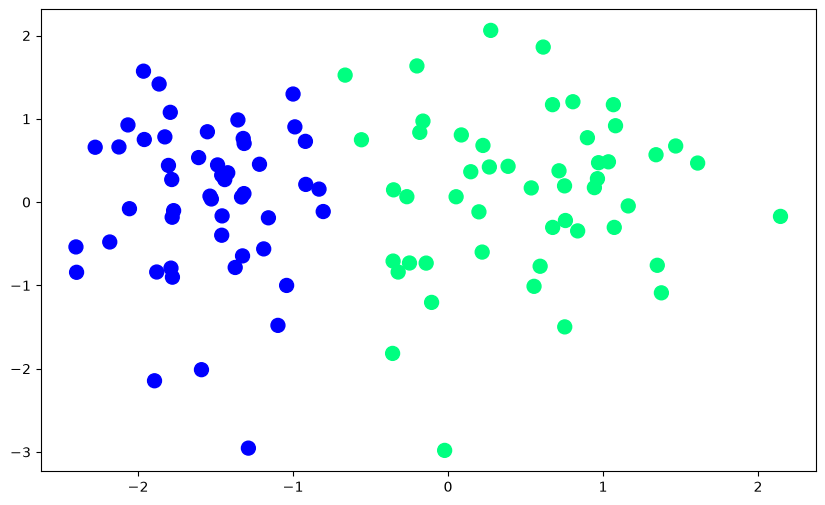

In [6]:
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0, n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

[1.4021669  0.17520236]
0.9
Value of m -8.003128038176095
Value of b -5.136917171425791


(-3.0, 2.0)

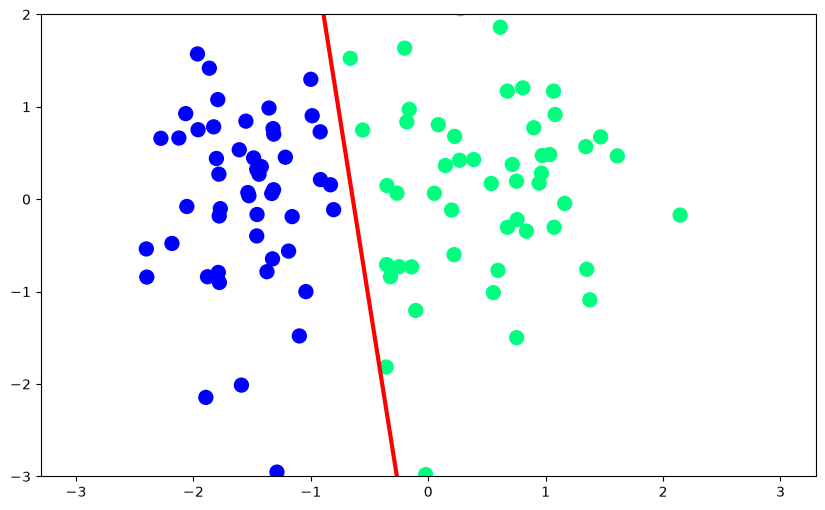

In [7]:
def myperceptron(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1
    
    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]
        
    return weights[0],weights[1:]
    
def step(z):
    return 1 if z>0 else 0


intercept_,coef_ = myperceptron(X,y)

print(coef_)
print(intercept_)

m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

print("Value of m", m)
print("Value of b", b)

x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

### Perceptron using hinge loss using self code 

Weight 1 0.9243919310080415
Weight 2 0.15134060762638524
Bias 1.4000000000000004
Value of m -6.108023124170937
Value of b 1.4000000000000004


(-3.0, 2.0)

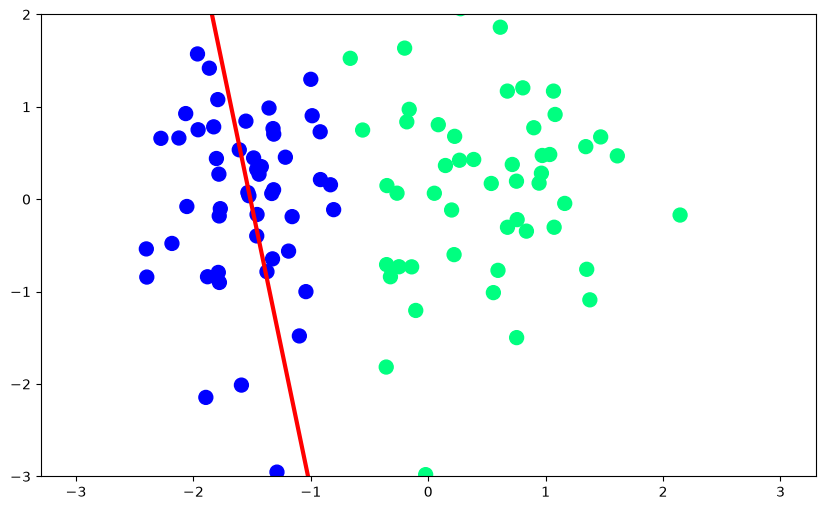

In [8]:
def hingelossperceptron(X,y):
    
    w1=w2=b=1
    lr = 0.1
    
    for j in range(1000):
    
        for i in range(X.shape[0]):

            # check condition
            z = w1*X[i][0] + w2*X[i][1] + b

            if z*y[i] < 0:
                w1 = w1 + lr*y[i]*X[i][0]
                w2 = w2 + lr*y[i]*X[i][1]
                b = b + lr*y[i]
            
    return w1,w2,b


w1,w2,b = hingelossperceptron(X,y)

print("Weight 1",w1)
print("Weight 2",w2)
print("Bias",b)

m = -(w1/w2)
c = -(b/w2)

print("Value of m", m)
print("Value of b", b)

x_input = np.linspace(-3,3,100)
y_input = m*x_input + c

plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

## Forward & Backward Propagation in Perceptron

### Regression

In [9]:
import numpy as np
import pandas as pd

In [10]:
df = pd.DataFrame([[8,8,4],[7,9,5],[6,10,6],[5,12,7]], columns=['cgpa', 'profile_score', 'lpa'])
df

,cgpa,profile_score,lpa
0,8,8,4
1,7,9,5
2,6,10,6
3,5,12,7


In [11]:
def initialize_parameters(layer_dims):

  np.random.seed(3)
  parameters = {}
  L = len(layer_dims)

  for l in range(1, L):

    parameters['W' + str(l)] = np.ones((layer_dims[l-1], layer_dims[l]))*0.1
    parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

  return parameters


def linear_forward(A_prev, W, b):
  Z = np.dot(W.T, A_prev) + b
  return Z

# Parameter initialization for a 2,2,1 type ANN architecture
parameters = initialize_parameters([2,2,1])

In [12]:
#W1 is first 4 weights
#W2 is second 2 weights
#b1 are 2 biases of 2 nodes
#b2 is bias of output nodes
parameters

{'W1': array([[0.1, 0.1],
        [0.1, 0.1]]),
 'b1': array([[0.],
        [0.]]),
 'W2': array([[0.1],
        [0.1]]),
 'b2': array([[0.]])}

In [13]:
# Forward Propagation
def L_layer_forward(X, parameters):

  A = X
  L = len(parameters) // 2                  # number of layers in the neural network

  for l in range(1, L+1):
    A_prev = A
    Wl = parameters['W' + str(l)]
    bl = parameters['b' + str(l)]
    print("A"+str(l-1)+": ", A_prev)
    print("W"+str(l)+": ", Wl)
    print("b"+str(l)+": ", bl)
    print("--"*20)

    A = linear_forward(A_prev, Wl, bl)
    print("A"+str(l)+": ", A)
    print("**"*20)

  return A,A_prev

In [14]:
X = df[['cgpa', 'profile_score']].values[0].reshape(2,1) # Shape(no of features, no. of training example)
y = df[['lpa']].values[0][0]
print(X)
print(y)

# Parameter initialization
parameters = initialize_parameters([2,2,1])

y_hat,A1 = L_layer_forward(X, parameters)
#A0 is [8,8] which is first rows inputs
#W1 and b1 are the weights calculated using those inputs
#A1 is output of A0 and input for first hidden layers 2 node
#Same weight, bias, input, output thing for A1 and A2 which is final answer

#Answer for A2 is 4lpa we got 3.2lpa

[[8]
 [8]]
4
A0:  [[8]
 [8]]
W1:  [[0.1 0.1]
 [0.1 0.1]]
b1:  [[0.]
 [0.]]
----------------------------------------
A1:  [[1.6]
 [1.6]]
****************************************
A1:  [[1.6]
 [1.6]]
W2:  [[0.1]
 [0.1]]
b2:  [[0.]]
----------------------------------------
A2:  [[0.32]]
****************************************


In [15]:
#Updating all 9 parameters

def update_parameters(parameters,y,y_hat,A1,X):
  parameters['W2'][0][0] = parameters['W2'][0][0] + (0.001 * 2 * (y - y_hat)*A1[0][0])
  parameters['W2'][1][0] = parameters['W2'][1][0] + (0.001 * 2 * (y - y_hat)*A1[1][0])
  parameters['b2'][0][0] = parameters['W2'][1][0] + (0.001 * 2 * (y - y_hat))

  parameters['W1'][0][0] = parameters['W1'][0][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0]*X[0][0])
  parameters['W1'][0][1] = parameters['W1'][0][1] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0]*X[1][0])
  parameters['b1'][0][0] = parameters['b1'][0][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0])

  parameters['W1'][1][0] = parameters['W1'][1][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0]*X[0][0])
  parameters['W1'][1][1] = parameters['W1'][1][1] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0]*X[1][0])
  parameters['b1'][1][0] = parameters['b1'][1][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0])

In [16]:
y_hat = y_hat[0][0]

#Now we have updated the parameters
update_parameters(parameters,y,y_hat,A1,X)
parameters

{'W1': array([[0.10658137, 0.10658137],
        [0.10658137, 0.10658137]]),
 'b1': array([[0.00082267],
        [0.00082267]]),
 'W2': array([[0.111776],
        [0.111776]]),
 'b2': array([[0.119136]])}

In [17]:
#Now repeat for 2 students and so on. Below is automated for loop use for inputting rows

In [18]:
# epochs implementation

parameters = initialize_parameters([2,2,1])
epochs = 5

for i in range(epochs):

  Loss = []

  for j in range(df.shape[0]):

    X = df[['cgpa', 'profile_score']].values[j].reshape(2,1) # Shape(no of features, no. of training example)
    y = df[['lpa']].values[j][0]

    # Parameter initialization


    y_hat,A1 = L_layer_forward(X,parameters)
    y_hat = y_hat[0][0]

    update_parameters(parameters,y,y_hat,A1,X)

    Loss.append((y-y_hat)**2)

  print('Epoch - ',i+1,'Loss - ',np.array(Loss).mean())

parameters

A0:  [[8]
 [8]]
W1:  [[0.1 0.1]
 [0.1 0.1]]
b1:  [[0.]
 [0.]]
----------------------------------------
A1:  [[1.6]
 [1.6]]
****************************************
A1:  [[1.6]
 [1.6]]
W2:  [[0.1]
 [0.1]]
b2:  [[0.]]
----------------------------------------
A2:  [[0.32]]
****************************************
A0:  [[7]
 [9]]
W1:  [[0.10658137 0.10658137]
 [0.10658137 0.10658137]]
b1:  [[0.00082267]
 [0.00082267]]
----------------------------------------
A1:  [[1.70612461]
 [1.70612461]]
****************************************
A1:  [[1.70612461]
 [1.70612461]]
W2:  [[0.111776]
 [0.111776]]
b2:  [[0.119136]]
----------------------------------------
A2:  [[0.50054357]]
****************************************
A0:  [[ 6]
 [10]]
W1:  [[0.11458955 0.1168776 ]
 [0.11458955 0.1168776 ]]
b1:  [[0.0019667]
 [0.0019667]]
----------------------------------------
A1:  [[1.83539945]
 [1.87200826]]
****************************************
A1:  [[1.83539945]
 [1.87200826]]
W2:  [[0.12712927]
 [0.127

{'W1': array([[0.26507636, 0.38558861],
        [0.27800387, 0.40980287]]),
 'b1': array([[0.02749056],
        [0.02974394]]),
 'W2': array([[0.41165744],
        [0.48302736]]),
 'b2': array([[0.48646246]])}

### Classification

In [19]:
import numpy as np
import pandas as pd

In [20]:
df = pd.DataFrame([[8,8,1],[7,9,1],[6,10,0],[5,5,0]], columns=['cgpa', 'profile_score', 'placed'])

df.head()

,cgpa,profile_score,placed
0,8,8,1
1,7,9,1
2,6,10,0
3,5,5,0


In [21]:
def initialize_parameters(layer_dims):

  np.random.seed(3)
  parameters = {}
  L = len(layer_dims)

  for l in range(1, L):
    parameters['W' + str(l)] = np.ones((layer_dims[l-1], layer_dims[l]))*0.1
    parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

  return parameters


# Utility Functions
def sigmoid(Z):
  A = 1/(1+np.exp(-Z))
  return A

def linear_forward(A_prev, W, b):
  Z = np.dot(W.T, A_prev) + b
  A = sigmoid(Z)
  return A

## Customer Churn Prediction using ANN

In [22]:
#This is a binary class propagation

In [23]:
import numpy as np
import pandas as pd

In [24]:
df = pd.read_csv(r"DataSets/Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [28]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [29]:
df.drop(columns=['RowNumber','CustomerId','Surname'],inplace=True)

In [30]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [31]:
#For One Hot Encoding
df = pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True)

In [32]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [33]:
X = df.drop(columns=['Exited'])
y = df['Exited']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [34]:
X_train.shape

(8000, 11)

In [35]:
y_train.shape

(8000,)

In [36]:
y.head()

0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

In [37]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_trf = scaler.fit_transform(X_train)
X_test_trf = scaler.transform(X_test)

In [38]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential 
from tensorflow.keras.layers import Dense

In [39]:
## Keras have Sequential and Non sequencial Model

In [40]:
model = Sequential()

#This is how you add hidden layers

#1st Hidden Layer with 3 nodes
model.add(Dense(11,activation='relu',input_dim=11))

#2nd Hidden Layer with 3 nodes
model.add(Dense(5,activation='relu',input_dim=11))

#Output Layer with 1 node
model.add(Dense(1,activation='sigmoid'))

c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [41]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 198 (792.00 B)

 Trainable params: 198 (792.00 B)

 Non-trainable params: 0 (0.00 B)

In [42]:
#loss is loss function and optimiser 
model.compile(optimizer='Adam',loss='binary_crossentropy')

In [43]:
# history = model.fit(X_train,y_train,batch_size=50,epochs=100,verbose=1,validation_split=0.2)
# validation_id_split will give val accuracy, val loss and accuracy
history = model.fit(X_train_trf,y_train,epochs=20)

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 695us/step - loss: 0.6975
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 667us/step - loss: 0.6124
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 699us/step - loss: 0.5546
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 690us/step - loss: 0.4518
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 652us/step - loss: 0.3904
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 658us/step - loss: 0.3701
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step - loss: 0.3619
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 700us/step - loss: 0.3573
Epoch 9/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step - loss: 0.3541
Epoch 10/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 663us/step - loss: 0.3517
Epoch 11/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - loss: 0.3499
Epoch 12/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step - loss: 0.3480
Epoch 13/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 658us/step - loss: 0.3471
Epoch 14/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 668us/step - loss: 0.3457
Epoch 15/20
250/250 ━━━━━━━━━

In [44]:
model.layers[0].get_weights()

[array([[-2.0941031e-01,  2.6424285e-03, -4.0729442e-01, -6.5194003e-02,
         -3.9643191e-02, -1.3987638e-01,  1.6302149e-01, -2.7487237e-02,
          2.4770676e-01, -3.6615279e-02,  2.5162897e-01],
        [-1.2695675e-01,  1.2633346e-01,  1.6081791e-01, -3.5518754e-02,
          6.7746305e-01,  7.7754557e-01, -1.2271739e-01, -5.3161446e-02,
         -3.6660099e-01, -8.6420780e-01, -3.4257317e-01],
        [-4.5811465e-01,  9.5645241e-02, -4.2649057e-02, -8.3824387e-03,
          5.5857867e-02, -1.0559897e-02, -1.0812633e-01,  3.4163335e-01,
          7.5547345e-02, -7.5396881e-02, -5.6805078e-02],
        [-1.8198057e-01, -1.4694563e-01,  4.5412514e-01, -1.1391838e-01,
          9.2922643e-02, -5.2908415e-01, -7.6771164e-01, -6.7344588e-01,
          4.1121566e-01, -7.4432358e-02, -6.5375614e-01],
        [-3.6880443e-01,  1.0354257e+00, -4.9673197e-01, -3.0377457e-02,
          6.8510830e-01, -7.6764721e-01, -3.7104559e-01, -4.0400252e-02,
         -2.2729808e-01, -2.9731631e-0

In [45]:
y_log = model.predict(X_test_trf)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 810us/step


In [46]:
y_pred = np.where(y_log > 0.5, 1, 0)

In [47]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.857

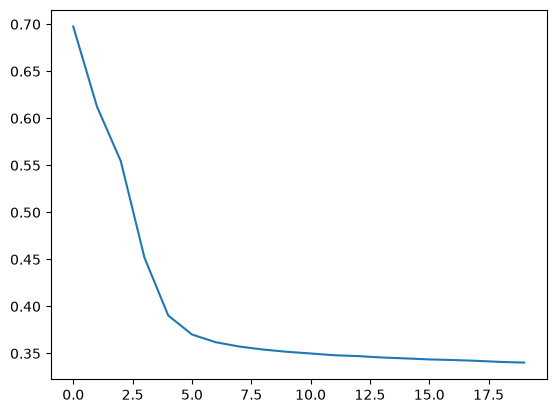

In [48]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])

### MULTICLASS CLASSIFICATION USING MNIST DATASET 

In [49]:
import numpy as np
import pandas as pd
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input,Dense,Flatten

In [50]:
#Dataset is so famous that train test split is already done
#(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()   # not working due to college proxy

df = np.load(r"DataSets/mnist.npz")


X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


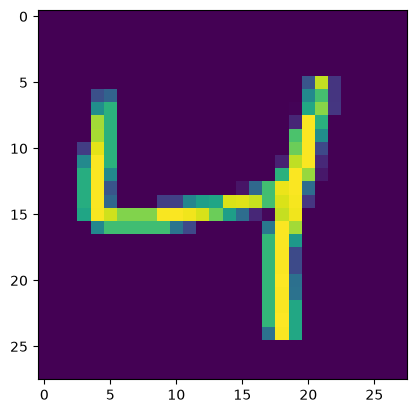

In [51]:
import matplotlib.pyplot as plt
plt.imshow(X_train[2])

In [52]:
X_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [53]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [54]:
#values are from 0 to 255 so need to be scaled

In [55]:
X_train = X_train/255
X_test = X_test/255

In [56]:
#using Model and adding different number of hidden layers
model = Sequential()

model.add(Input(shape=(28,28)))
model.add(Flatten())    #This will flatten the 28x28 numpy array into a 1D array of size 28*28

#Hidden Layers
model.add(Dense(128,activation='relu'))
model.add(Dense(32,activation='relu'))
model.add(Dense(10,activation='softmax'))

In [57]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
#loss function
#optimizers
#metrics
model.compile(loss='sparse_categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [59]:
#Training Models
history = model.fit(X_train,y_train,epochs=25,validation_split=0.2)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9167 - loss: 0.2853 - val_accuracy: 0.9576 - val_loss: 0.1532
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9642 - loss: 0.1212 - val_accuracy: 0.9650 - val_loss: 0.1208
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9741 - loss: 0.0847 - val_accuracy: 0.9714 - val_loss: 0.0961
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9795 - loss: 0.0640 - val_accuracy: 0.9722 - val_loss: 0.0965
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9843 - loss: 0.0499 - val_accuracy: 0.9725 - val_loss: 0.0977
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9876 - loss: 0.0395 - val_accuracy: 0.9738 - val_loss: 0.1019
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9886 - loss: 0.0338 - val_accuracy: 0.9716 - val_loss: 0.1037
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9911 - loss: 0.0257 - 

In [60]:
y_prob = model.predict(X_test)
y_prob
#This will give the probability of value that might be on the image

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 577us/step


array([[5.6599403e-16, 1.2363271e-11, 1.6135551e-14, ..., 1.0000000e+00,
        8.7317862e-14, 3.1519115e-10],
       [2.6449429e-21, 4.2051718e-12, 1.0000000e+00, ..., 3.2646170e-25,
        1.8820706e-14, 9.7606888e-29],
       [2.8352686e-16, 9.9999988e-01, 3.6367608e-12, ..., 5.8309915e-08,
        6.7868385e-08, 2.3999705e-10],
       ...,
       [3.1275824e-35, 3.5475379e-24, 8.3487255e-37, ..., 2.9025021e-18,
        1.5373672e-18, 2.5174329e-17],
       [4.9935855e-23, 7.3081627e-28, 2.2207481e-30, ..., 3.0584383e-23,
        4.6012930e-10, 3.1437565e-26],
       [7.1413672e-23, 4.2667377e-19, 5.3420988e-20, ..., 7.2504915e-27,
        3.4749042e-16, 3.1326192e-21]], shape=(10000, 10), dtype=float32)

In [61]:
y_pred = y_prob.argmax(axis=1)
y_pred
#This will give the value which has the max probability

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [62]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9751

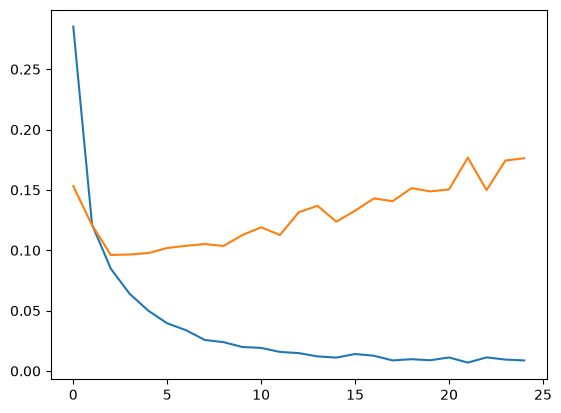

In [63]:
plt.plot(history.history['loss'])    #this is training loss
plt.plot(history.history['val_loss'])

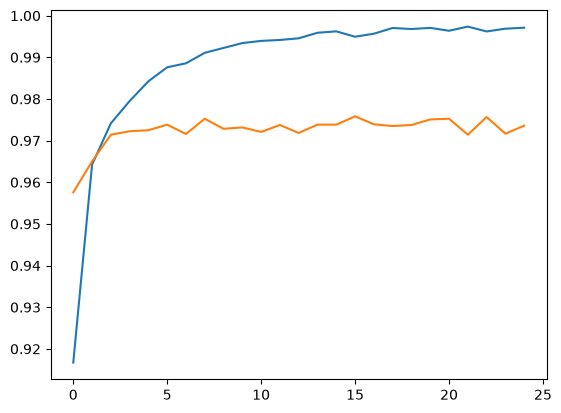

In [64]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

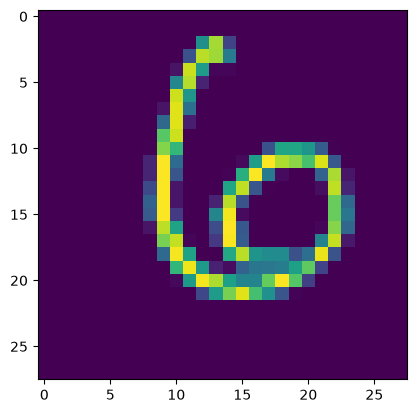

In [65]:
plt.imshow(X_test[100])

In [66]:
model.predict(X_test[100].reshape(1,28,28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


array([6])

# How to improve efficiency of a Neural Network

## 1) Early Stopping

In [67]:
import numpy as np
import pandas as pd

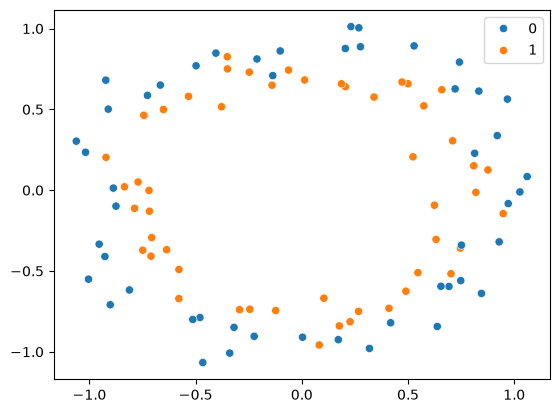

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=100, noise=0.1, random_state=1)
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y)
plt.show()

In [69]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2)

In [70]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

#keras model and its hidden layers
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [71]:
callback = EarlyStopping(monitor="val_loss", min_delta=0.00001, patience=20, verbose=1, mode="auto", baseline=None,     restore_best_weights=False)

#monitor -> is quantity to be monitored
#min_delta -> min value ot be qualified as an improvement
#patience -> no. of epochs with no improvements after which training must be stopped 
#verbose -> whether display message on callback or not
#mode -> when to stop
#baseline -> number where training will stop if no improvement
#restore_best_weights -> whther to restore best value of weights from previous data

In [72]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.4750 - loss: 0.6925 - val_accuracy: 0.3000 - val_loss: 0.7050
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5250 - loss: 0.6904 - val_accuracy: 0.3500 - val_loss: 0.7076
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5500 - loss: 0.6889 - val_accuracy: 0.3500 - val_loss: 0.7107
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5500 - loss: 0.6874 - val_accuracy: 0.3500 - val_loss: 0.7121
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5500 - loss: 0.6864 - val_accuracy: 0.3500 - val_loss: 0.7141
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5625 - loss: 0.6859 - val_accuracy: 0.4000 - val_loss: 0.7151
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5500 - loss: 0.6845 - val_accuracy: 0.4500 - val_loss: 0.7158
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5500 - loss: 0.6842 - val_accuracy: 0.4500 - v

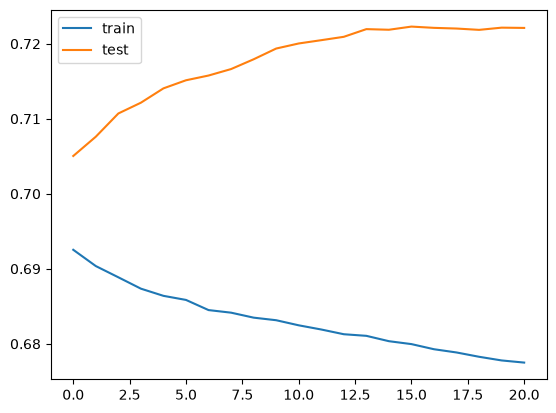

In [73]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

## 2) Feature Scaling/ Normalization and Standardization

In [74]:
import numpy as np
import pandas as pd

In [75]:
df = pd.read_csv('DataSets/Social_Network_Ads.csv')
df = df.drop(columns=['User ID', 'Gender'])
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


<Axes: xlabel='Age', ylabel='EstimatedSalary'>

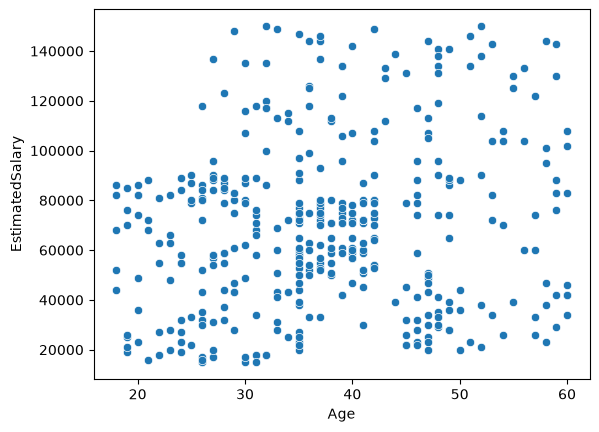

In [76]:
import seaborn as sns

sns.scatterplot(x=df.iloc[:,0],y=df.iloc[:,1])

In [77]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [78]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [79]:
#Using this you can see that unnormalised input gives a bad accuracy and hard to grasp trend

model = Sequential()

model.add(Dense(128,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

model.summary()

model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history = model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=50)

c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5719 - loss: 1634.8875 - val_accuracy: 0.4000 - val_loss: 606.6761
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4719 - loss: 392.6773 - val_accuracy: 0.6000 - val_loss: 448.9860
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4344 - loss: 225.7752 - val_accuracy: 0.6000 - val_loss: 142.5130
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4844 - loss: 127.0459 - val_accuracy: 0.6000 - val_loss: 107.3183
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5844 - loss: 144.9182 - val_accuracy: 0.4000 - val_loss: 92.3252
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5344 - loss: 25.9562 - val_accuracy: 0.4000 - val_loss: 36.8840
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5156 - loss: 61.3752 - val_accuracy: 0.6000 - val_loss: 182.0960
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4906 - loss: 161.0576 - val_

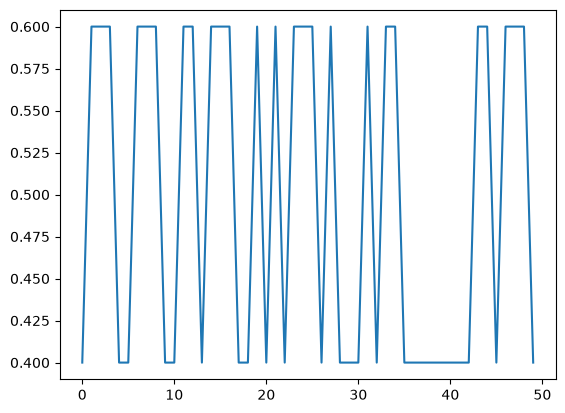

In [80]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])

In [81]:
#Using this you can see that unnormalised input gives a bad accuracy and hard to grasp trend

In [82]:
# Applying scaling

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

<Axes: >

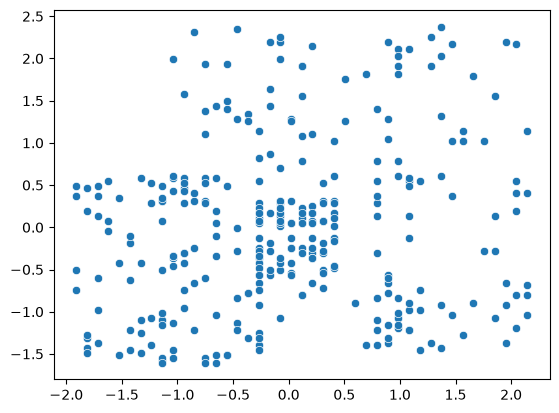

In [83]:
sns.scatterplot(x=X_train_scaled[:,0],y=X_train_scaled[:,1])

In [84]:
model = Sequential()

model.add(Dense(128,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history = model.fit(X_train_scaled,y_train,validation_data=(X_test_scaled,y_test),epochs=50)

Epoch 1/50


c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5719 - loss: 0.6982 - val_accuracy: 0.7625 - val_loss: 0.6638
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7812 - loss: 0.6379 - val_accuracy: 0.7625 - val_loss: 0.6060
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7812 - loss: 0.5894 - val_accuracy: 0.7750 - val_loss: 0.5567
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7937 - loss: 0.5476 - val_accuracy: 0.7750 - val_loss: 0.5156
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8125 - loss: 0.5117 - val_accuracy: 0.7875 - val_loss: 0.4811
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8156 - loss: 0.4814 - val_accuracy: 0.7875 - val_loss: 0.4526
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8219 - loss: 0.4541 - val_accuracy: 0.8000 - val_loss: 0.4274
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8375 - loss: 0.4307 - val_accuracy: 0.8000 - val_loss: 0.4043
Ep

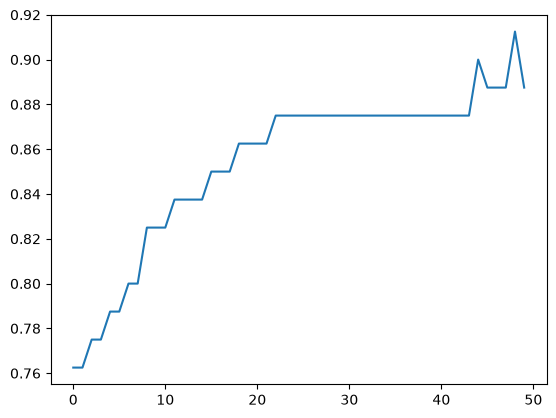

In [85]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])

In [86]:
#Accuracy increasing constantly

## 3) Vanishing gradient

In [87]:
import numpy as np
import pandas as pd

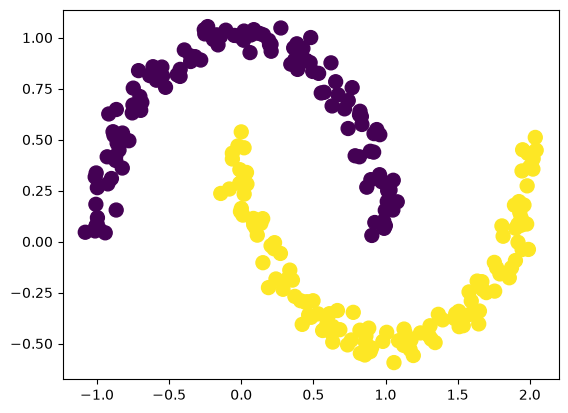

In [88]:
from sklearn.datasets import make_moons
X,y = make_moons(n_samples=250, noise=0.05, random_state=42)

plt.scatter(X[:,0],X[:,1], c=y, s=100)
plt.show()

In [89]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy',metrics=['accuracy'])

old_weights = model.get_weights()[0]
old_weights

array([[ 0.2503115 , -0.3191983 ,  0.1918022 ,  0.63856703, -0.21380016,
        -0.26880687,  0.48077005,  0.04736209, -0.24146315, -0.12187618],
       [ 0.0106318 , -0.01034623,  0.54648966,  0.17353642, -0.3086292 ,
         0.51599556, -0.46133602,  0.37318808,  0.36254317,  0.0651378 ]],
      dtype=float32)

In [90]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

model.fit(X_train, y_train, epochs = 50)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5100 - loss: 0.7429  
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7312 
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7245 
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7191 
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7140 
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7100 
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7051 
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7026 
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.7010 
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.6984 
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.6968 
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5100 - loss: 0.6953 


In [91]:
new_weights = model.get_weights()[0]
new_weights

array([[ 0.2501833 , -0.31886604,  0.19165488,  0.6382068 , -0.21355285,
        -0.2689083 ,  0.48062122,  0.04708716, -0.24136654, -0.12156764],
       [ 0.01073092, -0.01060242,  0.5465967 ,  0.17385186, -0.30880955,
         0.5160741 , -0.46121067,  0.3733897 ,  0.36247155,  0.06490717]],
      dtype=float32)

In [92]:
# To find the learning rate of my model
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [93]:
gradient = (old_weights - new_weights)/0.0010000000474974513
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [94]:
gradient

array([[ 0.12817979, -0.33226606,  0.14732778,  0.36025044, -0.24731456,
         0.1014173 ,  0.1488328 ,  0.27493387, -0.09661912, -0.30854344],
       [-0.09912252,  0.2561826 , -0.10704993, -0.31544265,  0.18033384,
        -0.07855891, -0.12534857, -0.2016127 ,  0.07161498,  0.23063271]],
      dtype=float32)

In [95]:
percent_change

array([[0.05120811, 0.10409394, 0.07681235, 0.05641545, 0.11567558,
        0.03772869, 0.03095717, 0.58049357, 0.04001402, 0.2531614 ],
       [0.9323212 , 2.4760954 , 0.01958865, 0.18177319, 0.05843058,
        0.01522473, 0.02717077, 0.05402442, 0.0197535 , 0.35406893]],
      dtype=float32)

In [96]:
old_weights

array([[ 0.2503115 , -0.3191983 ,  0.1918022 ,  0.63856703, -0.21380016,
        -0.26880687,  0.48077005,  0.04736209, -0.24146315, -0.12187618],
       [ 0.0106318 , -0.01034623,  0.54648966,  0.17353642, -0.3086292 ,
         0.51599556, -0.46133602,  0.37318808,  0.36254317,  0.0651378 ]],
      dtype=float32)

In [97]:
new_weights

array([[ 0.2501833 , -0.31886604,  0.19165488,  0.6382068 , -0.21355285,
        -0.2689083 ,  0.48062122,  0.04708716, -0.24136654, -0.12156764],
       [ 0.01073092, -0.01060242,  0.5465967 ,  0.17385186, -0.30880955,
         0.5160741 , -0.46121067,  0.3733897 ,  0.36247155,  0.06490717]],
      dtype=float32)

In [98]:
#as you can see very little difference in new and old weights and very small percentage 

### to fix this

In [99]:
# 1) Decrease number of hidden layers
# 2) Use a different activation function preferably RELU
# 3) Proper weight Initialization
# 4) Batch Normalization
# 5) Using residual Network

## 4) Drop-Out Layers

In [100]:
import numpy as np
import pandas as pd


import tensorflow as tf


from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [101]:
# Generating Data

X_train = np.linspace(-1, 1, 20)
y_train = np.array([-0.6561 , -0.3099 , -0.59035, -0.50855, -0.285  , 
                    -0.2443 , -0.02445,  0.00135, -0.2006 ,  0.07475, 
                    -0.1422 ,  0.06515,  0.15265,  0.3521 ,  0.28415,  
                    0.5524 ,  0.23115,  0.20835, 0.4211,  0.60485])
X_test = np.linspace(-1, 1, 20)
y_test = np.array([-0.69415, -0.451  , -0.43005, -0.4484 , -0.1475 ,
                   -0.5019 , -0.28055,  0.24595, -0.21425, -0.0286 ,  
                   0.23415,  0.46575, 0.07955,  0.1973 ,  0.0719 ,
                   0.3639 ,  0.5536 ,  0.3365 , 0.50705,  0.33435])

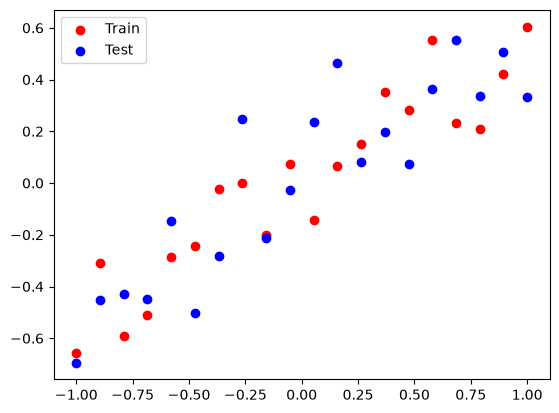

In [102]:
import matplotlib.pyplot as plt

plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.legend()
plt.show()

### Regression Model without Dropout

In [103]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam

#making hidden layers and running the models
model_1 = Sequential()

model_1.add(Dense(128, input_dim=1, activation="relu"))
model_1.add(Dense(128, activation="relu"))
model_1.add(Dense(1, activation="linear"))

adam = Adam(learning_rate=0.01)

model_1.compile(loss='mse', optimizer=adam, metrics=['mse'])
history = model_1.fit(X_train, y_train, epochs=100, validation_data = (X_test, y_test), verbose=1)


# evaluate the model
_, train_mse = model_1.evaluate(X_train, y_train, verbose=0)
_, test_mse = model_1.evaluate(X_test, y_test, verbose=0)
print('Train: {}, Test: {}'.format(train_mse, test_mse))

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 536ms/step - loss: 0.1516 - mse: 0.1516 - val_loss: 0.0314 - val_mse: 0.0314
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0213 - mse: 0.0213 - val_loss: 0.0466 - val_mse: 0.0466
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0368 - mse: 0.0368 - val_loss: 0.0395 - val_mse: 0.0395
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0289 - mse: 0.0289 - val_loss: 0.0298 - val_mse: 0.0298
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0178 - mse: 0.0178 - val_loss: 0.0372 - val_mse: 0.0372
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0241 - mse: 0.0241 - val_loss: 0.0387 - val_mse: 0.0387
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0250 - mse: 0.0250 - val_loss: 0.0320 - val_mse: 0.0320
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0186 - mse: 0.0186 - val_loss: 0.0290 - val_mse: 0.0290
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0163 - mse:

In [104]:
y_pred_1 = model_1.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


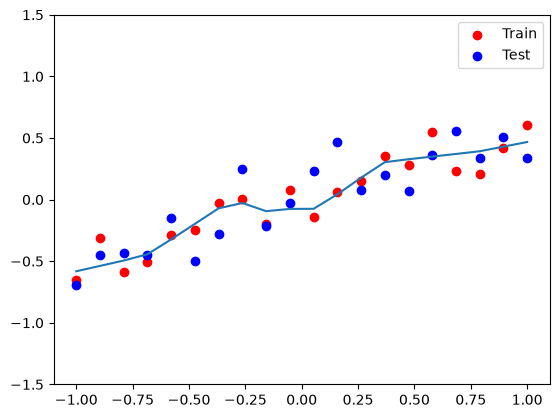

In [105]:
plt.figure()
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.plot(X_test, y_pred_1)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.show()

In [106]:
#As you can see the model is overfitting or will overfit for 500 epochs models not running fast enough so cannot do 500

### Regression Model with Dropout

model_2 = Sequential()
model_2.add(Dense(128, input_dim=1, activation="relu"))
model_2.add(Dropout(0.2))
model_2.add(Dense(128, activation="relu"))
model_2.add(Dropout(0.2))
model_2.add(Dense(1, activation="linear"))
adam = Adam(learning_rate=0.01)
model_2.compile(loss='mse', optimizer=adam, metrics=['mse'])

drop_out_history = model_2.fit(X_train, y_train, epochs=100, validation_data = (X_test, y_test), verbose=True)

In [107]:
# evaluate the model
_, train_mse = model_1.evaluate(X_train, y_train, verbose=0)
_, test_mse = model_1.evaluate(X_test, y_test, verbose=0)
print('Train: {}, Test: {}'.format(train_mse, test_mse))

Train: 0.011762741021811962, Test: 0.03525269776582718


In [108]:
y_pred_2 = model_1.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


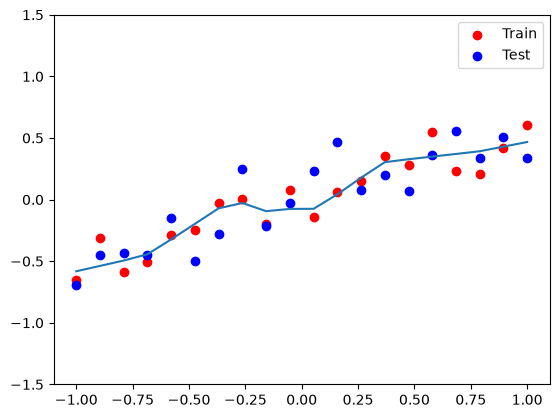

In [109]:
plt.figure()
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.plot(X_test, y_pred_2)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.show()

In [110]:
# Now model is more generalized

### CLassification Model without Dropout

In [111]:
import numpy as np
import matplotlib.pyplot as plt

In [112]:
#Generating Data

X = np.array([[-1.58986e-01,  4.23977e-01],
       [-3.47926e-01,  4.70760e-01],
       [-5.04608e-01,  3.53801e-01],
       [-5.96774e-01,  1.14035e-01],
       [-5.18433e-01, -1.72515e-01],
       [-2.92627e-01, -2.07602e-01],
       [-1.58986e-01, -4.38596e-02],
       [-5.76037e-02,  1.43275e-01],
       [-7.14286e-02,  2.71930e-01],
       [-2.97235e-01,  3.47953e-01],
       [-4.17051e-01,  2.01754e-01],
       [-4.40092e-01,  8.77193e-03],
       [-3.24885e-01, -3.21637e-02],
       [-2.46544e-01,  5.55556e-02],
       [-2.18894e-01,  2.01754e-01],
       [-3.43318e-01,  1.60819e-01],
       [-5.09217e-01,  7.89474e-02],
       [-3.84793e-01, -9.06433e-02],
       [-1.49770e-01,  1.25731e-01],
       [-1.95853e-01,  3.24561e-01],
       [-3.91705e-02, -2.19298e-01],
       [-1.08295e-01, -3.01170e-01],
       [-1.86636e-01, -3.30409e-01],
       [-2.18894e-01, -4.23977e-01],
       [-8.06452e-02, -5.64327e-01],
       [ 6.68203e-02, -5.17544e-01],
       [ 9.44700e-02, -3.24561e-01],
       [ 1.86636e-01, -1.66667e-01],
       [ 6.22120e-02, -7.30994e-02],
       [ 2.07373e-02, -1.95906e-01],
       [ 2.99539e-02, -3.42105e-01],
       [-9.90783e-02, -3.77193e-01],
       [-6.91244e-03, -4.64912e-01],
       [ 1.31336e-01, -4.29825e-01],
       [ 2.32719e-01, -1.95906e-01],
       [ 8.52535e-02, -8.47953e-02],
       [-1.31336e-01, -2.36842e-01],
       [ 2.30415e-03, -1.25731e-01],
       [ 1.22120e-01, -2.92398e-03],
       [-3.47926e-01, -3.12865e-01],
       [-2.28111e-01, -1.25731e-01],
       [-7.60369e-02,  1.46199e-02],
       [ 4.37788e-02,  2.04678e-02],
       [ 1.15207e-02,  1.54971e-01],
       [-4.17051e-01, -1.60819e-01],
       [-3.15668e-01, -3.18713e-01],
       [ 1.26728e-01, -2.19298e-01],
       [ 2.05069e-01, -3.12865e-01],
       [ 2.18894e-01, -4.59064e-01],
       [ 7.14286e-02, -6.46199e-01],
       [-1.31336e-01, -6.05263e-01],
       [-2.09677e-01, -5.81871e-01],
       [-2.28111e-01, -4.29825e-01],
       [-1.45161e-01, -4.12281e-01],
       [-6.68203e-02, -4.82456e-01],
       [ 1.35945e-01, -5.11696e-01],
       [ 2.69585e-01, -4.06433e-01],
       [ 2.97235e-01, -2.95322e-01],
       [ 2.74194e-01, -1.72515e-01],
       [ 2.55760e-01, -4.97076e-02],
       [ 2.23502e-01, -4.97076e-02],
       [ 1.82028e-01, -8.47953e-02],
       [ 1.58986e-01, -1.54971e-01],
       [ 7.14286e-02, -2.13450e-01],
       [ 1.61290e-02, -2.66082e-01],
       [-2.53456e-02, -3.83041e-01],
       [-1.15207e-02, -4.82456e-01],
       [-2.30415e-03, -5.05848e-01],
       [ 2.53456e-02, -5.11696e-01],
       [ 2.53456e-02, -5.58480e-01],
       [ 1.15207e-02, -6.57895e-01],
       [-4.83871e-02, -6.46199e-01],
       [-8.52535e-02, -5.52632e-01],
       [-9.90783e-02, -5.00000e-01],
       [-1.61290e-02, -4.23977e-01],
       [ 1.31336e-01, -3.59649e-01],
       [ 2.23502e-01, -3.71345e-01],
       [ 2.92627e-01, -3.01170e-01],
       [ 2.60369e-01, -2.07602e-01],
       [ 2.00461e-01, -2.25146e-01],
       [ 1.72811e-01, -2.71930e-01],
       [-1.31336e-01,  9.06433e-02],
       [-1.49770e-01,  7.30994e-02],
       [-2.41935e-01,  6.14035e-02],
       [-3.01843e-01,  1.78363e-01],
       [-2.97235e-01,  1.95906e-01],
       [-2.74194e-01,  3.07018e-01],
       [-3.24885e-01,  2.95322e-01],
       [-3.98618e-01,  2.66082e-01],
       [-4.35484e-01,  1.60819e-01],
       [-4.72350e-01,  7.89474e-02],
       [-3.38710e-01,  4.38596e-02],
       [-2.69585e-01,  4.38596e-02],
       [-2.55760e-01,  1.02339e-01],
       [-1.68203e-01,  2.66082e-01],
       [-1.12903e-01,  3.01170e-01],
       [-3.91705e-02,  3.47953e-01],
       [-1.26728e-01,  4.41520e-01],
       [-2.32719e-01,  4.41520e-01],
       [-3.38710e-01,  4.18129e-01],
       [-4.12442e-01,  3.53801e-01],
       [-5.09217e-01,  2.19298e-01],
       [-5.41475e-01,  1.46199e-02],
       [-5.04608e-01, -1.25731e-01],
       [-4.90783e-01, -1.43275e-01],
       [-3.61751e-01, -1.37427e-01],
       [-2.69585e-01, -8.47953e-02],
       [-2.23502e-01, -7.89474e-02],
       [-1.86636e-01, -3.80117e-02],
       [-1.54378e-01, -8.77193e-03],
       [-1.12903e-01,  5.55556e-02],
       [-8.52535e-02,  1.37427e-01],
       [-8.52535e-02,  2.77778e-01],
       [-1.68203e-01,  3.01170e-01],
       [-1.91244e-01,  1.95906e-01],
       [-1.40553e-01, -4.97076e-02],
       [-2.99539e-02,  6.72515e-02],
       [-2.00461e-01, -2.30994e-01],
       [-1.08295e-01, -8.47953e-02],
       [ 3.45622e-02,  6.72515e-02],
       [ 8.06452e-02,  1.19883e-01],
       [-3.85369e-01,  3.30409e-02],
       [-3.81221e-01,  1.31287e-01],
       [-3.52189e-01,  2.58187e-01],
       [-3.54263e-01,  3.64620e-01],
       [-4.14401e-01, -6.92982e-02],
       [-4.99424e-01, -3.24561e-02],
       [-2.98272e-01, -9.79532e-02],
       [-3.16935e-01, -1.83918e-01],
       [-3.68779e-01, -2.90351e-01],
       [-3.56336e-01, -3.96784e-01],
       [-2.71313e-01,  4.38596e-03],
       [-1.77995e-01,  8.62573e-02],
       [-2.46429e-01,  1.43567e-01],
       [-2.50576e-01,  2.29532e-01],
       [-2.21544e-01,  3.76901e-01],
       [-2.15323e-01,  2.95029e-01],
       [-1.30300e-01,  2.17251e-01],
       [-2.07028e-01,  2.89474e-02],
       [-9.71198e-02,  2.13158e-01],
       [-3.90553e-02,  2.58187e-01],
       [ 1.90092e-02,  4.01462e-01],
       [-3.69816e-02,  4.21930e-01],
       [-6.39401e-02,  3.31871e-01],
       [-1.30300e-01,  3.76901e-01],
       [-3.75000e-01, -4.37719e-01],
       [-3.95737e-01, -3.51754e-01],
       [-3.54263e-01, -2.08480e-01],
       [-4.37212e-01, -3.76316e-01],
       [-4.80760e-01, -5.03216e-01],
       [-4.10253e-01, -4.66374e-01],
       [-2.48502e-01, -2.57602e-01],
       [-2.27765e-01, -3.14912e-01],
       [-2.83756e-01, -3.84503e-01],
       [-2.92051e-01, -4.54094e-01],
       [-3.37673e-01, -5.19591e-01],
       [-2.77535e-01, -5.48246e-01],
       [-2.07028e-01, -5.35965e-01],
       [-1.86290e-01, -4.78655e-01],
       [-1.32373e-01, -5.07310e-01],
       [-1.77995e-01, -2.98538e-01],
       [-1.65553e-01, -1.75731e-01],
       [-1.61406e-01, -1.26608e-01],
       [ 3.45622e-04,  2.58187e-01],
       [ 7.91475e-02,  3.56433e-01],
       [-2.66129e-02,  1.80409e-01],
       [-5.35714e-02,  7.80702e-02],
       [-1.41705e-02, -5.29240e-02],
       [-7.01613e-02, -1.63450e-01],
       [-6.39401e-02, -2.94444e-01],
       [-3.07604e-02, -4.66374e-01],
       [-5.77189e-02, -5.27778e-01],
       [-5.35714e-02, -3.96784e-01],
       [ 5.21889e-02, -4.17251e-01],
       [-1.62442e-02, -1.67544e-01],
       [-6.39401e-02, -8.56725e-02],
       [-6.18664e-02, -1.60819e-02],
       [-3.80184e-03,  4.38596e-03],
       [ 4.18203e-02,  2.04971e-01],
       [ 7.91475e-02,  1.92690e-01],
       [ 4.59677e-02,  2.54094e-01],
       [ 1.18548e-01,  1.92690e-01],
       [ 1.10253e-01,  8.62573e-02],
       [ 1.08180e-01, -6.92982e-02],
       [ 1.66244e-01, -2.42690e-02],
       [ 1.41359e-01,  6.57895e-02],
       [ 1.43433e-01,  1.68129e-01],
       [ 1.70392e-01,  1.92690e-01],
       [ 1.08180e-01,  2.99123e-01],
       [ 1.18548e-01,  3.19591e-01],
       [ 1.26843e-01,  3.93275e-01],
       [-8.67512e-02,  4.21930e-01],
       [-4.73502e-02,  5.07895e-01],
       [ 2.52304e-02,  5.20175e-01],
       [ 6.25576e-02,  5.52924e-01],
       [-5.87558e-03,  4.42398e-01],
       [-5.14977e-02,  5.73392e-01],
       [-8.05300e-02,  5.07895e-01],
       [-1.53111e-01,  5.52924e-01],
       [-1.11636e-01,  5.48830e-01],
       [-1.63479e-01,  4.91520e-01],
       [-2.52650e-01, -1.88012e-01],
       [-2.46429e-01, -3.65497e-02],
       [-3.21083e-01, -4.33626e-01],
       [-3.31452e-01, -6.05556e-01],
       [-3.85369e-01, -5.15497e-01],
       [-3.99885e-01, -6.21930e-01],
       [-1.24078e-01, -1.26608e-01],
       [-3.16935e-01, -2.28947e-01],
       [-2.94124e-01, -1.34795e-01],
       [-1.53111e-01,  1.84503e-01]])


y = np.array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0.,
       0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       0., 1., 1., 1., 1., 0., 0.])

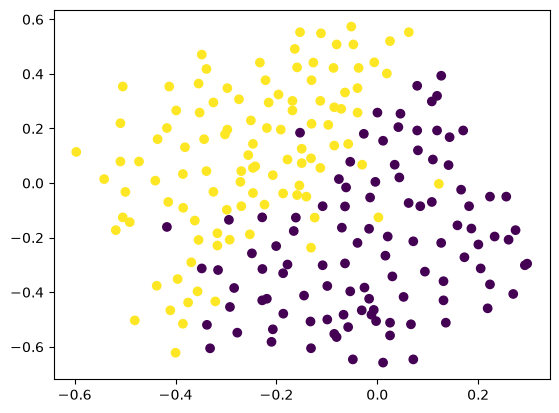

In [113]:
import matplotlib.pyplot as plt
plt.scatter(X[:,0], X[:,1], c=y)
plt.show()

In [114]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam

In [115]:
model = Sequential()

model.add(Dense(128, input_dim=2, activation="relu"))
model.add(Dense(128, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

adam = Adam(learning_rate=0.01)
model.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history = model.fit(X, y, epochs=150, validation_split = 0.2,verbose=0)

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 3s 356us/step


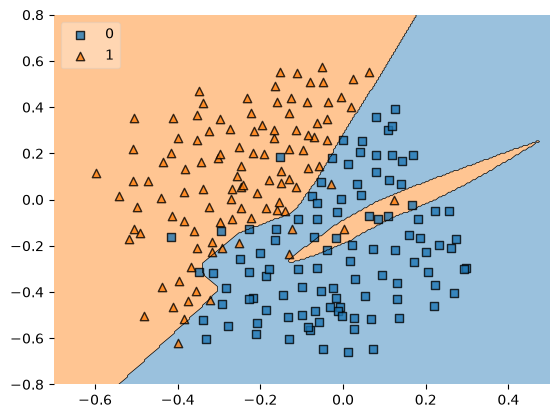

In [116]:
from mlxtend.plotting import plot_decision_regions

class KerasClassifierWrapper:
    def __init__(self, model):
        self.model = model
    def predict(self, X):
        preds = self.model.predict(X)
        # for binary classification with sigmoid output:
        return (preds > 0.5).astype(int).reshape(-1)
        # for multi-class with softmax output, use instead:
        # return np.argmax(preds, axis=1)

wrapped_model = KerasClassifierWrapper(model)

plot_decision_regions(X, y.astype('int'), clf=wrapped_model, legend=2)
plt.xlim(-0.7,0.5)
plt.ylim(-0.8,0.8)
plt.show()

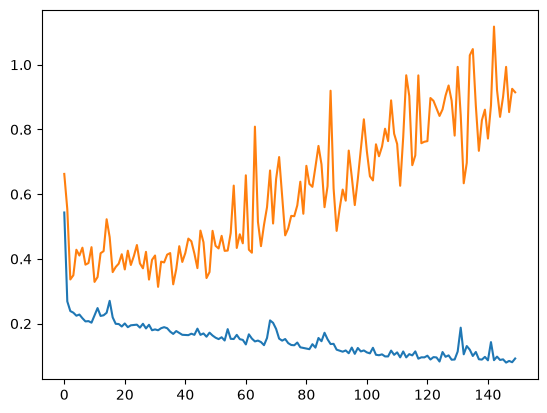

In [117]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

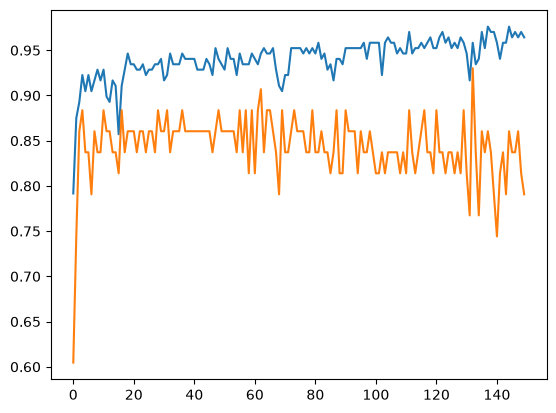

In [118]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

### CLassification Model with Dropout

In [119]:
model = Sequential()

model.add(Dense(128, input_dim=2, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(1, activation="sigmoid"))

adam = Adam(learning_rate=0.01)
model.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history = model.fit(X, y, epochs=150, validation_split = 0.2,verbose=0)

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 3s 350us/step


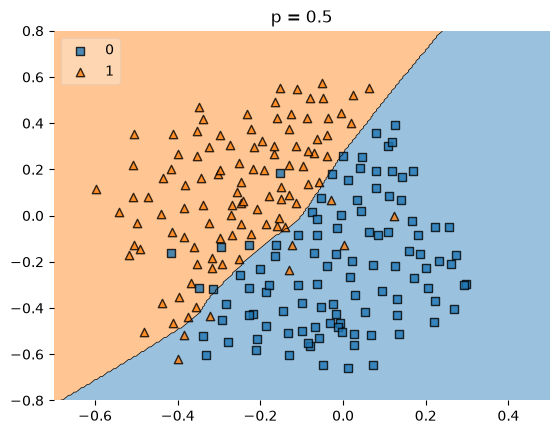

In [120]:
wrapped_model = KerasClassifierWrapper(model)
plot_decision_regions(X, y.astype('int'), clf=wrapped_model, legend=2)
plt.xlim(-0.7,0.5)
plt.ylim(-0.8,0.8)
plt.title('p = 0.5')
plt.show()

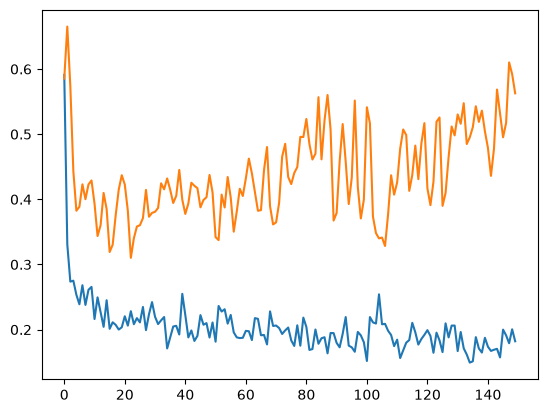

In [121]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

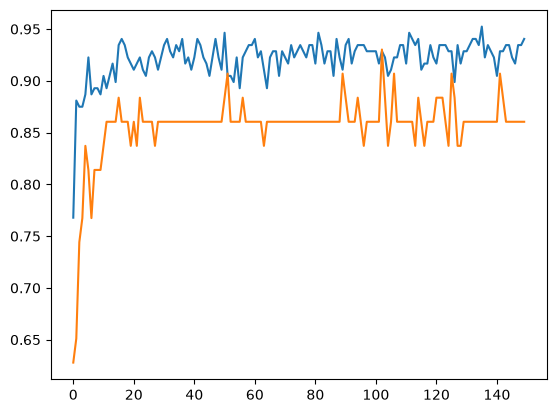

In [122]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

## 5) Regularization

In [123]:
import numpy as np

import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam

In [124]:
from sklearn.datasets import make_moons
X, y = make_moons(100, noise=0.25,random_state=2)

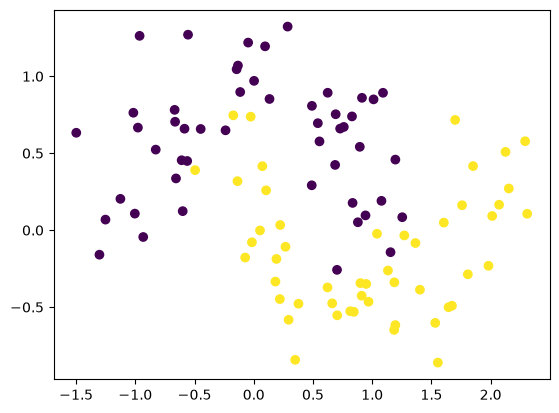

In [125]:
import matplotlib.pyplot as plt
plt.scatter(X[:,0], X[:,1], c=y)
plt.show()

In [126]:
import time

start = time.time()
print("Import time:", time.time() - start)
model1 = Sequential()

model1.add(Dense(128,input_dim=2, activation="relu"))
model1.add(Dense(128, activation="relu"))
model1.add(Dense(1,activation='sigmoid'))
take1 = time.time()
model1.summary()
take2 = time.time()

Import time: 2.1457672119140625e-05


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_31 (Dense)                │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [127]:
take3 = time.time()
adam = Adam(learning_rate=0.01)
model1.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])
take4 = time.time()
history1 = model1.fit(X, y, epochs=200, validation_split = 0.2,verbose=1)
take5 = time.time()

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.6625 - loss: 0.6215 - val_accuracy: 0.9000 - val_loss: 0.3751
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8375 - loss: 0.4204 - val_accuracy: 0.9000 - val_loss: 0.2013
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8375 - loss: 0.3899 - val_accuracy: 0.9000 - val_loss: 0.1821
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8375 - loss: 0.3707 - val_accuracy: 0.9000 - val_loss: 0.2524
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8375 - loss: 0.3819 - val_accuracy: 0.9000 - val_loss: 0.2451
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8375 - loss: 0.3557 - val_accuracy: 0.9000 - val_loss: 0.1947
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8375 - loss: 0.3423 - val_accuracy: 0.9000 - val_loss: 0.1987
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8375 - loss: 0.3338 - val_accuracy: 0.9000 - val_loss:

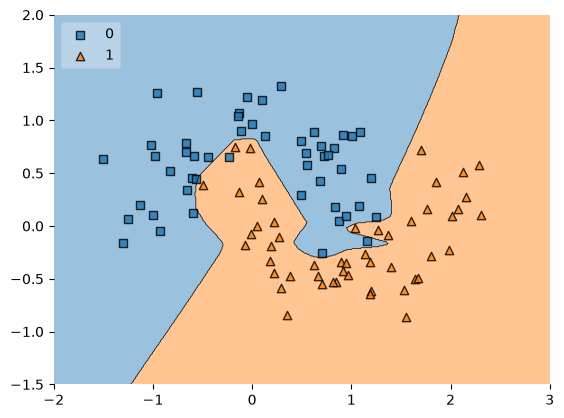

In [128]:
take6 = time.time()
class KerasClassifier:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        pred = self.model.predict(X, verbose=0)
        return (pred > 0.5).astype(int).ravel()

clf = KerasClassifier(model1)
take7 = time.time()
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X, y.astype(int), clf=clf, legend=2)
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()
take8 = time.time()

In [129]:
#as you can see out model is overfitting

In [130]:
print(type(model1))

<class 'keras.src.models.sequential.Sequential'>


In [131]:
take9= time.time()
model2 = Sequential()
take10 = time.time()
model2.add(Dense(128,input_dim=2, activation="relu",kernel_regularizer=tensorflow.keras.regularizers.l1(0.001)))
model2.add(Dense(128, activation="relu",kernel_regularizer=tensorflow.keras.regularizers.l1(0.001)))
model2.add(Dense(1,activation='sigmoid'))
take11 = time.time()
model2.summary()
take12 = time.time()
#here we are using regularization and its type

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_34 (Dense)                │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [132]:
take13 = time.time()
adam = Adam(learning_rate=0.01)
model2.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])
take14 = time.time()
history2 = model2.fit(X, y, epochs=200, validation_split = 0.2,verbose=1)
take15 = time.time()

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.7000 - loss: 1.7811 - val_accuracy: 0.9000 - val_loss: 1.3976
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7875 - loss: 1.3300 - val_accuracy: 0.9000 - val_loss: 0.9946
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8500 - loss: 1.0281 - val_accuracy: 0.9000 - val_loss: 0.7607
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8250 - loss: 0.8540 - val_accuracy: 0.9000 - val_loss: 0.6152
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8500 - loss: 0.7317 - val_accuracy: 0.9000 - val_loss: 0.6164
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8375 - loss: 0.7071 - val_accuracy: 0.9000 - val_loss: 0.6226
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8500 - loss: 0.6696 - val_accuracy: 0.9000 - val_loss: 0.5555
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8500 - loss: 0.6427 - val_accuracy: 0.9000 - val_loss:

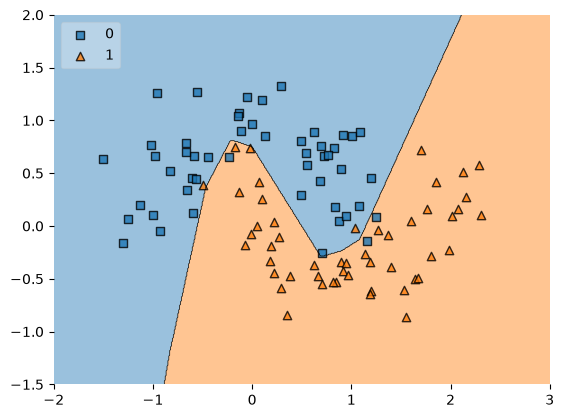

In [133]:
take16 = time.time()
clf = KerasClassifier(model2)
take17 = time.time()
plot_decision_regions(X, y.astype('int'), clf=clf, legend=2)
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()
take18 = time.time()

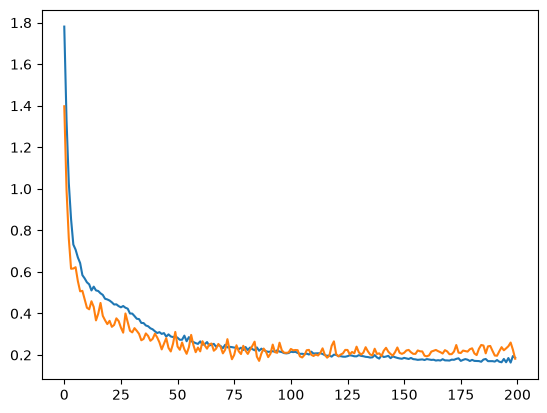

In [134]:
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])

In [135]:
print("Take1:", take1 - start)
print("Take2:", take2 - start)
print("Take3:", take3 - start)
print("Take4:", take4 - start)
print("Take5:", take5 - start)
print("Take6:", take6 - start)
print("Take7:", take7 - start)
print("Take8:", take8 - start)
print("Take9:", take9 - start)
print("Take10:", take10 - start)
print("Take11:", take11- start)
print("Take12:", take12- start)
print("Take13:", take13 - start)
print("Take14:", take14 - start)
print("Take15:", take15 - start)
print("Take16:", take16 - start)
print("Take17:", take17 - start)
print("Take18:", take18 - start)

Take1: 0.01482081413269043
Take2: 0.019633769989013672
Take3: 0.024534940719604492
Take4: 0.028705120086669922
Take5: 12.271261930465698
Take6: 12.277204751968384
Take7: 12.277323484420776
Take8: 16.996403217315674
Take9: 17.01712203025818
Take10: 17.017822265625
Take11: 17.0315682888031
Take12: 17.036990880966187
Take13: 17.043095111846924
Take14: 17.047483921051025
Take15: 29.415948152542114
Take16: 29.421898365020752
Take17: 29.421929121017456
Take18: 33.94110727310181


In [136]:
model1_weight_layer1 = model1.get_weights()[0].reshape(256)
model2_weight_layer1 = model2.get_weights()[0].reshape(256)

C:\Users\Akshat\AppData\Local\Temp\ipykernel_10624\2689867733.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model1_weight_layer1)
C:\Users\Akshat\AppData\Local\Temp\ipykernel_10624\2689867733.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model2_weight_layer1)


<Axes: ylabel='Density'>

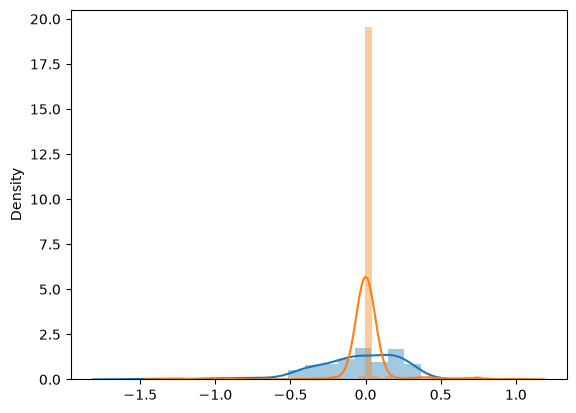

In [137]:
sns.distplot(model1_weight_layer1)
sns.distplot(model2_weight_layer1)
#This shows how our data is being centralised around 0

## 6) Weight Initialization

In [138]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [139]:
df = pd.read_csv('DataSets/ushape.csv')
df.head()

,X,Y,class
0,-1.049426,0.084443,0
1,0.922818,0.457489,0
2,0.656787,0.699597,0
3,1.188940,-0.386528,1
4,0.289265,-0.137745,1


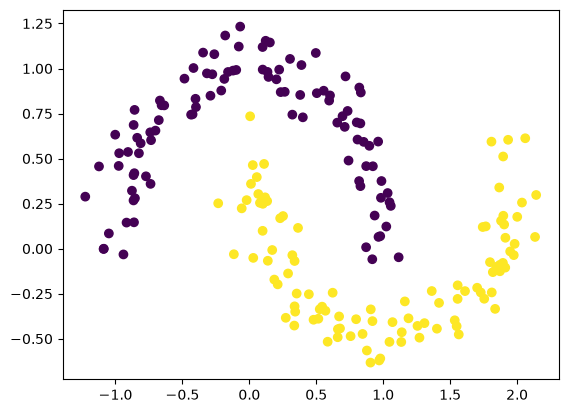

In [140]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [141]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [142]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [143]:
model = Sequential()

model.add(Dense(2,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))
#For different activation function weight initialization acts differently
model.summary()

c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_37 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

In [144]:
model.get_weights()
#These are default weights set by keras

[array([[ 0.42958474, -1.1925844 ],
        [-0.58100826, -0.44911826]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.4589647 ],
        [0.44758296]], dtype=float32),
 array([0.], dtype=float32)]

In [145]:
# Set parameters to 0
initial_weights = model.get_weights()
initial_weights[0] = np.zeros(model.get_weights()[0].shape)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.zeros(model.get_weights()[2].shape)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)

#initial_weights[3] = np.ones(model.get_weights()[3].shape)*0.5
#initial_weights[3] = np.random.randn(model.get_weights()[3].shape[0],model.get_weights()[3].shape[1])

In [146]:
model.set_weights(initial_weights)
model.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [147]:
#Now you can train model and get on with it and see how it changes accuracy

In [148]:
#model.add(Dense(10,activation='relu',input_dim=2,kernel_initializer='he_normal'))
# Setting up weight initializer
# default is glorat

## 7) Batch Normalization

In [149]:
# just this to do batch normalization


# model = Sequential()

# model.add(Dense(3,activation='relu',input_dim=2))
# model.add(BatchNormalization())
# model.add(Dense(2,activation='relu'))
# model.add(BatchNormalization())
# model.add(Dense(1,activation='sigmoid'))

# model.summary()

## 8) Optimizers

In [150]:
import pandas as pd
import numpy as np

In [151]:
df = pd.read_csv('DataSets/DailyDelhiClimateTest.csv')
df = df[['date', 'meantemp']]
df.head()

,date,meantemp
0,2017-01-01,15.913043
1,2017-01-02,18.500000
2,2017-01-03,17.111111
3,2017-01-04,18.700000
4,2017-01-05,18.388889


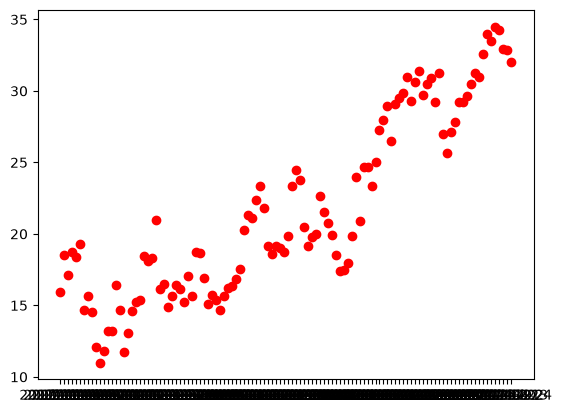

In [152]:
import matplotlib.pyplot as plt
plt.scatter(x=df['date'], y= df['meantemp'], color = 'red')

### 8a) Exponentially Weighted Moving Average

In [153]:
x1 = df['meantemp'].ewm(alpha=0.9).mean()
x2 = df['meantemp'].ewm(alpha=0.5).mean()
x3 = df['meantemp'].ewm(alpha=0.3).mean()
#beta = 1 - alpha

In [154]:
x1

0      15.913043
1      18.264822
2      17.225443
3      18.552677
4      18.405266
         ...    
109    34.403401
110    34.265340
111    33.036534
112    32.891153
113    32.089115
Name: meantemp, Length: 114, dtype: float64

In [155]:
df['ewma'] = x1
df.head()

,date,meantemp,ewma
0,2017-01-01,15.913043,15.913043
1,2017-01-02,18.500000,18.264822
2,2017-01-03,17.111111,17.225443
3,2017-01-04,18.700000,18.552677
4,2017-01-05,18.388889,18.405266


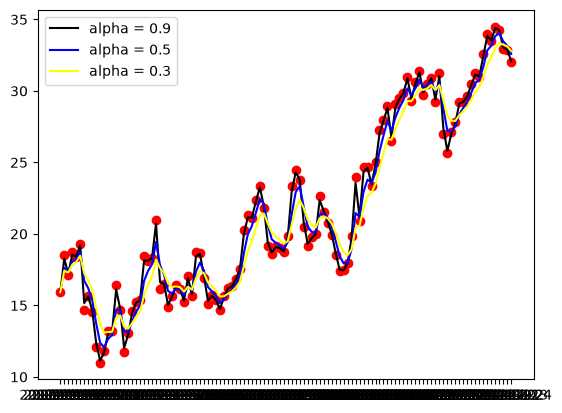

In [156]:
plt.scatter(x=df['date'], y=df['meantemp'], color='red')
plt.plot(df['date'], x1, color='black', label = 'alpha = 0.9')
plt.plot(df['date'], x2, color='blue', label = 'alpha = 0.5')
plt.plot(df['date'], x3, color='yellow', label = 'alpha = 0.3')
plt.legend()
plt.show()

### 8b) SGD Optimizer with Plain, Momentum and Nag

In [157]:
import tensorflow as tf
mera_optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.0,  nesterov=False, name="SGD")

#learning_rate -> Default is 0.01
#momentum -> Momentum coefficient. 0.0 means no momentum (plain SGD). A common value is 0.9.
#nesterov -> If True, uses Nesterov Accelerated Gradient (NAG). Requires momentum > 0.
#name -> Name assigned to the optimizer. Usually left as "SGD".
#**kwargs -> Additional optional arguments inherited from the base Optimizer class. Most users don't need to specify these.


#Plain SGD
#optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)


#SGD with Momentum
#optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)


#SGD with Nesterov
#optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)

### 8c) Optimizers with Adagrad

In [158]:
import tensorflow as tf

meraoptimzer = tf.keras.optimizers.Adagrad(learning_rate=0.001, initial_accumulator_value=0.1, epsilon=1e-7, name="Adagrad")

# learning_rate -> Initial learning rate (default = 0.001)
# initial_accumulator_value -> Initial value of the accumulated squared gradients. Usually leave at the default (0.1).
# epsilon -> Small constant added to the denominator to prevent division by zero.
# name -> Name of the optimizer.

### 8d) Optimizers with RMSprop

In [159]:
import tensorflow as tf

meraoptimzer= tf.keras.optimizers.RMSprop(learning_rate=0.001, rho=0.9, momentum=0.0, epsilon=1e-7, centered=False, name="RMSprop")

# learning_rate -> Initial learning rate (default = 0.001)
# rho -> Discounting factor for the moving average of squared gradients. Default = 0.9.
# momentum -> Momentum coefficient. Default = 0.0.
# epsilon -> Small constant to avoid division by zero.
# centered -> If True, normalizes gradients using an estimate of their variance. Usually left as False.
# name -> Name of the optimizer.

# Plain RMSprop
optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.001)

# RMSprop with Momentum
optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.001, momentum=0.9)

### 8e) Optimizers with Adam

In [160]:
import tensorflow as tf

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-7, amsgrad=False, name="Adam")


# beta_1 -> Exponential decay rate for the first moment (moving average of gradients). Default = 0.9.
# beta_2 -> Exponential decay rate for the second moment (moving average of squared gradients). Default = 0.999.
# amsgrad -> If True, uses the AMSGrad variant of Adam. Usually left as False.
# name -> Name assigned to the optimizer.

# Default Adam
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Adam with custom learning rate
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

# Adam with AMSGrad
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, amsgrad=True)

# Adam with custom beta values
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.95, beta_2=0.999)

# Hyperparameter Tuning Left

# CNN

## Padding and Strides

In [161]:
import numpy as np
import tensorflow
from tensorflow import keras
from keras.layers import Dense,Conv2D,Flatten
from keras import Sequential

In [162]:
df = np.load(r"DataSets/mnist.npz")


X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

In [163]:
#Architecture of CNN

#Padding
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu', input_shape=(28,28,1)))
# 32 nodes with each of size 3,3 with padding valid
model.add(Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu'))
model.add(Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu'))

model.add(Flatten())
#Data converted to 1D

model.add(Dense(128,activation='relu'))
model.add(Dense(10,activation='softmax'))

c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [164]:
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 22, 22, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 15488)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 128)            │     1,982,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,002,698 (7.64 MB)

 Trainable params: 2,002,698 (7.64 MB)

 Non-trainable params: 0 (0.00 B)

In [165]:
#Above you can see that image size is decreasing as we go deeper into the layers

In [166]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='same',strides=(2,2), activation='relu', input_shape=(28,28,1)))
#parameter named strides with a value in form of tupple
model.add(Conv2D(32,kernel_size=(3,3),padding='same',strides=(2,2), activation='relu'))
model.add(Conv2D(32,kernel_size=(3,3),padding='same',strides=(2,2), activation='relu'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(10,activation='softmax'))

In [167]:
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,770 (335.04 KB)

 Trainable params: 85,770 (335.04 KB)

 Non-trainable params: 0 (0.00 B)

## Pooling

In [168]:
import numpy as np
import tensorflow
from tensorflow import keras
from keras.layers import Dense,Conv2D,Flatten
from keras import Sequential
from tensorflow.keras.layers import MaxPooling2D

In [169]:
df = np.load(r"DataSets/mnist.npz")


X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

In [170]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu', input_shape=(28,28,1)))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))
model.add(Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(10,activation='softmax'))

In [171]:
model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 128)            │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,386 (442.91 KB)

 Trainable params: 113,386 (442.91 KB)

 Non-trainable params: 0 (0.00 B)

## Lenet Architecture

In [172]:
import numpy as np
import tensorflow
from tensorflow import keras
from keras.layers import Dense,Conv2D,Flatten
from keras import Sequential
from tensorflow.keras.layers import MaxPooling2D, AveragePooling2D

In [173]:
df = np.load(r"DataSets/mnist.npz")


X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

In [174]:
model = Sequential()

model.add(Conv2D(6,kernel_size=(5,5),padding='valid', activation='tanh', input_shape=(32,32,1)))
model.add(AveragePooling2D(pool_size=(2, 2), strides=2, padding='valid'))

model.add(Conv2D(16,kernel_size=(5,5),padding='valid', activation='tanh'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

model.add(Flatten())

model.add(Dense(120,activation='tanh'))
model.add(Dense(84,activation='tanh'))
model.add(Dense(10,activation='softmax'))

In [175]:
model.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

## Data Augmentation

In [176]:
#### This is how to handle less data and reduce overfitting by generating data by self

In [177]:
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [178]:
img = image.load_img("DataSets/cat.jpg", target_size=(200,200))

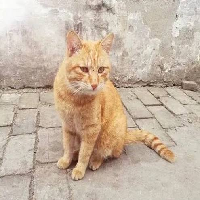

In [179]:
img

In [180]:
datagen = ImageDataGenerator(rotation_range = 0.2, shear_range = 0.2, zoom_range = 0.2, horizontal_flip = True, vertical_flip = True, width_shift_range = 0.2, height_shift_range=0.2)

In [181]:
img = image.img_to_array(img)

In [182]:
img.shape

(200, 200, 3)

In [183]:
input_batch = img.reshape(1,200,200,3)

In [184]:
i=0

for output in datagen.flow(input_batch, batch_size=1, save_to_dir='aug'):

    i = i+1

    if i == 10:
        break

In [185]:
input_batch.shape

(1, 200, 200, 3)

In [186]:
#You can see different phtotos in aug folder

## Transfer Learning

# RNN

In [187]:
#Two techniques to convert text into vector
# Integer Encoding and One Hot Encoding

In [188]:
#Integer Method
import numpy as np

docs = ['go india', 'india india', 'hip hip hurray', 'jeetega bhai jeetega india jeetega', 'bharat mata ki jai', 'kohli kohli', 'sachin sachin', 'dhoni dhoni', 'modi ji ki jai', 'inquilab zindabad']

In [189]:
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer(oov_token='<nothing>')
#converts all words into tokens and all new words are changed into nothing

In [190]:
tokenizer.fit_on_texts(docs)

In [191]:
tokenizer.word_index
#word and its token

{'<nothing>': 1,
 'india': 2,
 'jeetega': 3,
 'hip': 4,
 'ki': 5,
 'jai': 6,
 'kohli': 7,
 'sachin': 8,
 'dhoni': 9,
 'go': 10,
 'hurray': 11,
 'bhai': 12,
 'bharat': 13,
 'mata': 14,
 'modi': 15,
 'ji': 16,
 'inquilab': 17,
 'zindabad': 18}

In [192]:
tokenizer.word_counts
#word and its frequency

OrderedDict([('go', 1),
             ('india', 4),
             ('hip', 2),
             ('hurray', 1),
             ('jeetega', 3),
             ('bhai', 1),
             ('bharat', 1),
             ('mata', 1),
             ('ki', 2),
             ('jai', 2),
             ('kohli', 2),
             ('sachin', 2),
             ('dhoni', 2),
             ('modi', 1),
             ('ji', 1),
             ('inquilab', 1),
             ('zindabad', 1)])

In [193]:
tokenizer.document_count
#No. of rows / No. of sentences

10

In [194]:
#words into sequences
sequences = tokenizer.texts_to_sequences(docs)
sequences

[[10, 2],
 [2, 2],
 [4, 4, 11],
 [3, 12, 3, 2, 3],
 [13, 14, 5, 6],
 [7, 7],
 [8, 8],
 [9, 9],
 [15, 16, 5, 6],
 [17, 18]]

In [195]:
#padding
from keras.utils import pad_sequences
sequences = pad_sequences(sequences,padding='post')
sequences

array([[10,  2,  0,  0,  0],
       [ 2,  2,  0,  0,  0],
       [ 4,  4, 11,  0,  0],
       [ 3, 12,  3,  2,  3],
       [13, 14,  5,  6,  0],
       [ 7,  7,  0,  0,  0],
       [ 8,  8,  0,  0,  0],
       [ 9,  9,  0,  0,  0],
       [15, 16,  5,  6,  0],
       [17, 18,  0,  0,  0]], dtype=int32)

In [196]:
from keras.datasets import imdb
from keras import Sequential
from keras.layers import Dense,SimpleRNN,Embedding,Flatten

In [197]:
import numpy as np

df = np.load(r"DataSets/imdb.npz", allow_pickle=True)

X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

In [198]:
X_train

array([list([23022, 309, 6, 3, 1069, 209, 9, 2175, 30, 1, 169, 55, 14, 46, 82, 5869, 41, 393, 110, 138, 14, 5359, 58, 4477, 150, 8, 1, 5032, 5948, 482, 69, 5, 261, 12, 23022, 73935, 2003, 6, 73, 2436, 5, 632, 71, 6, 5359, 1, 25279, 5, 2004, 10471, 1, 5941, 1534, 34, 67, 64, 205, 140, 65, 1232, 63526, 21145, 1, 49265, 4, 1, 223, 901, 29, 3024, 69, 4, 1, 5863, 10, 694, 2, 65, 1534, 51, 10, 216, 1, 387, 8, 60, 3, 1472, 3724, 802, 5, 3521, 177, 1, 393, 10, 1238, 14030, 30, 309, 3, 353, 344, 2989, 143, 130, 5, 7804, 28, 4, 126, 5359, 1472, 2375, 5, 23022, 309, 10, 532, 12, 108, 1470, 4, 58, 556, 101, 12, 23022, 309, 6, 227, 4187, 48, 3, 2237, 12, 9, 215]),
       list([23777, 39, 81226, 14, 739, 20387, 3428, 44, 74, 32, 1831, 15, 150, 18, 112, 3, 1344, 5, 336, 145, 20, 1, 887, 12, 68, 277, 1189, 403, 34, 119, 282, 36, 167, 5, 393, 154, 39, 2299, 15, 1, 548, 88, 81, 101, 4, 1, 3273, 14, 40, 3, 413, 1200, 134, 8208, 41, 180, 138, 14, 3086, 1, 322, 20, 4930, 28948, 359, 5, 3112, 2128, 1, 20045

In [199]:
len(X_train[2])

149

In [200]:
X_train[0]

[23022,
 309,
 6,
 3,
 1069,
 209,
 9,
 2175,
 30,
 1,
 169,
 55,
 14,
 46,
 82,
 5869,
 41,
 393,
 110,
 138,
 14,
 5359,
 58,
 4477,
 150,
 8,
 1,
 5032,
 5948,
 482,
 69,
 5,
 261,
 12,
 23022,
 73935,
 2003,
 6,
 73,
 2436,
 5,
 632,
 71,
 6,
 5359,
 1,
 25279,
 5,
 2004,
 10471,
 1,
 5941,
 1534,
 34,
 67,
 64,
 205,
 140,
 65,
 1232,
 63526,
 21145,
 1,
 49265,
 4,
 1,
 223,
 901,
 29,
 3024,
 69,
 4,
 1,
 5863,
 10,
 694,
 2,
 65,
 1534,
 51,
 10,
 216,
 1,
 387,
 8,
 60,
 3,
 1472,
 3724,
 802,
 5,
 3521,
 177,
 1,
 393,
 10,
 1238,
 14030,
 30,
 309,
 3,
 353,
 344,
 2989,
 143,
 130,
 5,
 7804,
 28,
 4,
 126,
 5359,
 1472,
 2375,
 5,
 23022,
 309,
 10,
 532,
 12,
 108,
 1470,
 4,
 58,
 556,
 101,
 12,
 23022,
 309,
 6,
 227,
 4187,
 48,
 3,
 2237,
 12,
 9,
 215]

In [201]:
X_train = pad_sequences(X_train,padding='post',maxlen=50)
X_test = pad_sequences(X_test,padding='post',maxlen=50)

In [202]:
X_train[0]

array([ 3724,   802,     5,  3521,   177,     1,   393,    10,  1238,
       14030,    30,   309,     3,   353,   344,  2989,   143,   130,
           5,  7804,    28,     4,   126,  5359,  1472,  2375,     5,
       23022,   309,    10,   532,    12,   108,  1470,     4,    58,
         556,   101,    12, 23022,   309,     6,   227,  4187,    48,
           3,  2237,    12,     9,   215], dtype=int32)

In [203]:
model = Sequential()

model.add(SimpleRNN(32,input_shape=(50,1),return_sequences=False))
model.add(Dense(1,activation='sigmoid'))

model.summary()

c:\Coding\Artificial Intelligence\Deep Learning\dl_tutorial\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [204]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

model.fit(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5086 - loss: 0.6946 - val_accuracy: 0.5075 - val_loss: 0.6945
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5108 - loss: 0.6927 - val_accuracy: 0.5069 - val_loss: 0.6939
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5084 - loss: 0.6926 - val_accuracy: 0.5023 - val_loss: 0.6957
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5048 - loss: 0.6928 - val_accuracy: 0.5018 - val_loss: 0.6964
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5079 - loss: 0.6923 - val_accuracy: 0.5058 - val_loss: 0.6944


### Sentiment Analysis

In [205]:
docs = ['go india', 'india india', 'hip hip hurray', 'jeetega bhai jeetega india jeetega', 'bharat mata ki jai', 'kohli kohli', 'sachin sachin', 'dhoni dhoni', 'modi ji ki jai', 'inquilab zindabad']


from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer()

In [206]:
tokenizer.fit_on_texts(docs)

In [207]:
len(tokenizer.word_index)

17

In [208]:
sequences = tokenizer.texts_to_sequences(docs)
sequences

[[9, 1],
 [1, 1],
 [3, 3, 10],
 [2, 11, 2, 1, 2],
 [12, 13, 4, 5],
 [6, 6],
 [7, 7],
 [8, 8],
 [14, 15, 4, 5],
 [16, 17]]

In [209]:
from keras.utils import pad_sequences
sequences = pad_sequences(sequences,padding='post')
sequences

array([[ 9,  1,  0,  0,  0],
       [ 1,  1,  0,  0,  0],
       [ 3,  3, 10,  0,  0],
       [ 2, 11,  2,  1,  2],
       [12, 13,  4,  5,  0],
       [ 6,  6,  0,  0,  0],
       [ 7,  7,  0,  0,  0],
       [ 8,  8,  0,  0,  0],
       [14, 15,  4,  5,  0],
       [16, 17,  0,  0,  0]], dtype=int32)

In [210]:
from keras import Sequential
from keras.layers import Embedding
from keras import Input

model = Sequential([Input(shape=(5,)), Embedding(input_dim=18, output_dim=2)])

model.summary()

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 5, 2)           │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36 (144.00 B)

 Trainable params: 36 (144.00 B)

 Non-trainable params: 0 (0.00 B)

In [211]:
model.compile('adam','accuracy')

In [212]:
pred = model.predict(sequences)
print(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
[[[ 0.04237531  0.03208593]
  [-0.00486837  0.0118531 ]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817]]

 [[-0.00486837  0.0118531 ]
  [-0.00486837  0.0118531 ]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817]]

 [[ 0.03831676 -0.01521387]
  [ 0.03831676 -0.01521387]
  [ 0.00748422  0.03964015]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817]]

 [[ 0.01844653 -0.02183159]
  [-0.00860254 -0.01159386]
  [ 0.01844653 -0.02183159]
  [-0.00486837  0.0118531 ]
  [ 0.01844653 -0.02183159]]

 [[ 0.0382189  -0.01101185]
  [ 0.04125198 -0.03883041]
  [-0.00946441  0.03628469]
  [ 0.01685065  0.0207209 ]
  [ 0.04580858 -0.00943817]]

 [[-0.02201321 -0.01757644]
  [-0.02201321 -0.01757644]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817]]

 [[ 0.00712723 -0.04814621]
  [ 0.00712723 -0.04814621]
  [ 0.04580858 -0.00943817]
  [ 0.04580858 -0.00943817

In [213]:
from keras.datasets import imdb
from keras import Sequential
from keras.layers import Dense,SimpleRNN,Embedding,Flatten

In [214]:
import numpy as np

df = np.load(r"DataSets/imdb.npz", allow_pickle=True)

X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

In [215]:
X_train = pad_sequences(X_train,padding='post',maxlen=50)
X_test = pad_sequences(X_test,padding='post',maxlen=50)

In [216]:
X_train.shape

(25000, 50)

In [217]:
model = Sequential()

model.add(Input(shape=(50,)))
model.add(Embedding(input_dim=100000, output_dim=2))
model.add(SimpleRNN(32))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 2)          │       200,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,153 (785.75 KB)

 Trainable params: 201,153 (785.75 KB)

 Non-trainable params: 0 (0.00 B)

In [218]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['acc'])
history = model.fit(X_train, y_train,epochs=5,validation_data=(X_test,y_test))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - acc: 0.6589 - loss: 0.5907 - val_acc: 0.7950 - val_loss: 0.4446
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - acc: 0.8477 - loss: 0.3598 - val_acc: 0.7972 - val_loss: 0.4529
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - acc: 0.9046 - loss: 0.2515 - val_acc: 0.8042 - val_loss: 0.4834
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - acc: 0.9330 - loss: 0.1863 - val_acc: 0.7972 - val_loss: 0.4946
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - acc: 0.9514 - loss: 0.1400 - val_acc: 0.7853 - val_loss: 0.5822


In [219]:
print(X_train.max())
print(X_test.max())

88582
88579


## Deep RNN 

In [220]:
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense,LSTM,GRU, Input

In [221]:
import numpy as np

df = np.load(r"DataSets/imdb.npz", allow_pickle=True)

X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

In [222]:
X_train = pad_sequences(X_train, maxlen=100)
X_test = pad_sequences(X_test, maxlen=100)

In [223]:
#Define RNN model
model = Sequential([Input(shape=(100,)), Embedding(input_dim=100000, output_dim=32), SimpleRNN(5, return_sequences=True), SimpleRNN(5), Dense(1, activation='sigmoid')])

model.summary()

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 32)        │     3,200,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 100, 5)         │           190 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,200,251 (12.21 MB)

 Trainable params: 3,200,251 (12.21 MB)

 Non-trainable params: 0 (0.00 B)

In [224]:
# Define the LSTM model
model = Sequential([Input(shape=(100,)), Embedding(input_dim=100000, output_dim=32), LSTM(5, return_sequences=True), LSTM(5), Dense(1, activation='sigmoid')])

model.summary()

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 32)        │     3,200,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100, 5)         │           760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5)              │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,200,986 (12.21 MB)

 Trainable params: 3,200,986 (12.21 MB)

 Non-trainable params: 0 (0.00 B)

In [225]:
# Define the GRU model
model = Sequential([Input(shape=(100,)), Embedding(input_dim=100000, output_dim=32), GRU(5, return_sequences=True), GRU(5), Dense(1, activation='sigmoid')])

model.summary()

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 100, 32)        │     3,200,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 100, 5)         │           585 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 5)              │           180 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,200,771 (12.21 MB)

 Trainable params: 3,200,771 (12.21 MB)

 Non-trainable params: 0 (0.00 B)

In [226]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2)

Epoch 1/5


625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.7481 - loss: 0.5012 - val_accuracy: 0.7974 - val_loss: 0.5091
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9018 - loss: 0.2522 - val_accuracy: 0.7256 - val_loss: 0.6764
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9556 - loss: 0.1318 - val_accuracy: 0.7120 - val_loss: 0.8641
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.9792 - loss: 0.0708 - val_accuracy: 0.6730 - val_loss: 1.1059
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.9889 - loss: 0.0399 - val_accuracy: 0.8420 - val_loss: 0.5896


## Bidirectional RNN

In [227]:
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense,LSTM,GRU, Input, Bidirectional

In [228]:
import numpy as np

df = np.load(r"DataSets/imdb.npz", allow_pickle=True)

X_train = df["x_train"]
y_train = df["y_train"]
X_test = df["x_test"]
y_test = df["y_test"]

In [229]:
X_train = pad_sequences(X_train, maxlen=100, padding='post', truncating='post')
X_test = pad_sequences(X_test, maxlen=100, padding='post', truncating='post')

In [230]:
model = Sequential([Input(shape=(100,)), Embedding(input_dim=100000, output_dim=32), Bidirectional(SimpleRNN(5)), Dense(1, activation='sigmoid')])

model.summary()

Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 100, 32)        │     3,200,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 10)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,200,391 (12.21 MB)

 Trainable params: 3,200,391 (12.21 MB)

 Non-trainable params: 0 (0.00 B)

In [231]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.6428 - loss: 0.6405 - val_accuracy: 0.7642 - val_loss: 0.6177
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.8359 - loss: 0.3988 - val_accuracy: 0.6138 - val_loss: 0.7416
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.9432 - loss: 0.1744 - val_accuracy: 0.6358 - val_loss: 0.8066
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.9785 - loss: 0.0831 - val_accuracy: 0.4242 - val_loss: 1.4900
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.9778 - loss: 0.0727 - val_accuracy: 0.5090 - val_loss: 1.3479
